# Where the model picks its coding algorithm: targeted vs random pushes (C2c)

**The experiment.** It runs on **Qwen3-8B** (pinned revision `b968826d…`, FP8 W8A8 on a 16 GB RTX 2000 Ada, thinking off, temperature 1). For most coding tasks the model writes the same algorithm almost every time: *union-find* for "count connected components" (T10), a *full sort* for "k-th smallest" (T03). An earlier iteration found that **random pushes** of the residual stream at the task-specification tokens sometimes make the model write a *different, correct* algorithm. This experiment asks **which** pushes do that, and whether a *plan subspace* `P_t` read from forward passes explains it.
- `P_t` is the span of the centroid differences `c_X − c_default` of the task-spec states (blocks 12–35). The states come from 30 forced *"Implement X"* paraphrases per algorithm X. A name-masked twin subspace is built from descriptions instead of names.
- 13,500 programs were sampled under **common random numbers (CRN)**. They were labelled by a runtime tracer + AST, with a blind LLM judge only on disagreement. Every predictor was sha256-committed before sampling.

**Headline results of the full run**

| Claim | Outcome |
|---|---|
| **C2a** (primary): the projection share π(u) on `P_t` ranks which random pushes move the algorithm | **Disconfirmed**: ρ < 0.2 on 6/6 tasks; pooled within-task ρ = 0.03 [−0.03, 0.09] |
| **Decomposition**: is the `P_t` component of escaping pushes needed? | **No**: removing it keeps the effect (pooled median R = 1.00) |
| **C2c**: a *targeted* push toward the runner-up centroid beats a random push of the same size | **Disconfirmed by its rule (5/6 tasks)**, but **T10 is a clean exception**: 48% correct DFS vs 0% (24/0 CRN flips, McNemar p = 1.2e-7); crossing at s = 0.59 vs the predicted 0.5 |
| **Novelty audit** | 0 novel algorithms among 10,651 correct push programs |

**What this notebook runs.** `method.py` is the orchestrator of 8 resumable stages. The GPU stages take 2.5 GPU-hours with the 8B model and cannot run in Colab; their product is one *label* per (task, arm, CRN slot). The notebook loads 100 of those CRN slots, **every C2c arm on T10 and T03**. It then runs the CPU **analysis stage for claim C2c** with the original code (`analysis/common.py`, `analysis/c2c.py`, `analysis/run_all.py::c2c`) and checks every number against the published `results/c2c.json`.

**Glossary**
- **Twin:** the neutral prompt with no push. It writes the default algorithm.
- **CRN slot** (task, template W1–W5, k): every arm uses the same sampling random numbers at a slot, so two arms at one slot differ only by the push.
- **Dose s:** the push moves the task-spec state by `s × D_l` along `r_l`, the unit direction from the default centroid to the runner-up centroid (`D_l` = their distance). **s = 0.5 is the predicted Voronoi midpoint `b_t`.**
- **ν(s):** the same dose in *ban units* (the per-position norm of an earlier ban's displacement). The random pushes of the population used α = 1–2 ban units.
- **Off-default share:** the fraction of valid programs that implement a catalogue algorithm other than the default.

In [1]:
import subprocess, sys
def _pip(*a): subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *a])

# Packages NOT pre-installed on Colab: none needed here. The stages that use torch / transformers / accelerate run
# on a GPU with the 8B model and are not executed in this notebook (see the orchestrator section).

# numpy, scipy, scikit-learn, matplotlib -- pre-installed on Colab, install locally only (at Colab's exact versions)
if 'google.colab' not in sys.modules:
    _pip('numpy==2.0.2', 'scipy==1.16.3', 'scikit-learn==1.6.1', 'matplotlib==3.10.0')

In [2]:
from __future__ import annotations

# method.py (orchestrator): original imports
import os
import subprocess
import sys
from pathlib import Path

# analysis/common.py, analysis/c2c.py, analysis/run_all.py (the C2c analysis path): original imports
import math
from collections import Counter, defaultdict
from typing import Any, Iterable

import numpy as np
from scipy import stats

# notebook additions: data loading, timing, the `C2C` module stand-in, plots
import json
import time
import types

import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap

In [3]:
GITHUB_DATA_URL = "https://raw.githubusercontent.com/ai-inventor-papers/ai-invention-295f8e-prompt-bans-substitute-not-just-subtract/fork/run_jSassd-YWLVC/round-4/experiment-22/demo/mini_demo_data.json"
import http.client
import json
import urllib.request
from pathlib import Path

def load_data():
    try:
        with urllib.request.urlopen(GITHUB_DATA_URL, timeout=15) as response:
            return json.loads(response.read().decode())
    # Network errors, timeouts, a placeholder URL, bad JSON, a cut-off response.
    except (OSError, ValueError, http.client.HTTPException) as e:
        print("GitHub data unavailable, using local mini_demo_data.json:", e)
    local = Path("mini_demo_data.json")
    if local.exists(): return json.loads(local.read_text())
    raise FileNotFoundError("Could not load mini_demo_data.json")

In [4]:
data = load_data()
_ex = data["datasets"][0]["examples"]
print(f"dataset {data['datasets'][0]['dataset']!r}: {len(_ex)} CRN slots; per task:",
      dict(Counter(e["metadata_task"] for e in _ex)))

GitHub data unavailable, using local mini_demo_data.json: HTTP Error 404: Not Found
dataset 'targeted': 100 CRN slots; per task: {'T03': 50, 'T10': 50}


## Configuration
The analysis has no training loop: its tunable parameters are the **resampling counts** of the original code (bootstrap CIs and rarefaction). The functions below take them as default arguments, so **re-run the definition cells after changing a value**.
- At the original values, the whole C2c analysis takes a few seconds and reproduces every published number exactly.
- At smaller values, the point estimates (shares, flips, McNemar p, s50) are unchanged and only the CIs move.
- The crossing CI needs more than 20 bootstrap fits; below that it is reported as unavailable.

In [5]:
# Resampling counts of the original analysis (bootstrap CIs and rarefaction); original values on the right.
N_BOOT_PAIRED = 2000    # paired CRN bootstrap over slots, targeted vs random (analysis/c2c.py paired; original: 2000)
N_BOOT_CROSSING = 1000  # bootstrap of the logistic 50% crossing dose s50 (analysis/c2c.py crossing; original: 1000)
N_SUB_RAREFY = 1000     # subsamples of the rarefied Hill-1 at depth 25 (analysis/common.py; original: 1000)

## 1. The orchestrator: `method.py`
`method.py` runs each stage of the experiment as a resumable subprocess:

| Stage | What it does | Needs |
|---|---|---|
| `s0` | input copies, sha256 + bench verification, the iteration-3 screen file (commit entry #0), labeller re-check | CPU |
| `prompts` | name-masked algorithm descriptions (alias-leak checked) and all 4,144 prompts | OpenRouter |
| `gpu1` | GPU unit tests, engine check (replicates the iteration-3 screen 180/180), prompt states, ban units, realised displacements | GPU + Qwen3-8B |
| `commit` | CPU tests, plan subspace `P_t` + all predictors, then the sha256 commitment (`predictions/c2_commit.json`) | CPU |
| `label` | label worker: runtime tracer + AST, blind LLM judge only on disagreement (concurrent with `gpu2`) | CPU + OpenRouter |
| `gpu2` | sampling stages A–H: 13,500 CRN-coupled programs in 20-row batches | GPU + Qwen3-8B |
| `analyze` | S7 analyses + figures (`analysis/run_all.py`) | CPU |
| `outputs` | `method_out.json` + two independent audits | CPU |

The code below is the original script. It has two notebook adaptations:
- a notebook has no `__file__`, so `ROOT` is the working directory;
- the module docstring is assigned to `__doc__` explicitly, because the `help` stage prints it.

In [6]:
__doc__ = """Where the model's algorithm choice lives -- orchestrator (Qwen3-8B, FP8 W8A8 on a 16 GB RTX 2000 Ada).

Stages (each resumable; see README.md):
  s0        input copies + sha256 + bench verification, screen file (entry #0), labeller re-check
  prompts   masked descriptions (OpenRouter, leak-checked) + all 4,144 prompts
  gpu1      GPU unit tests, engine check (screen replication), states, units, realised displacements
  commit    S3 plan subspace + predictors, then S4 commit (predictions/c2_commit.json, commitments.log)
  label     label worker (run concurrently with gpu2)
  gpu2      S5 sampling stages A-H
  analyze   S7 analyses + figures (analysis/run_all.py)
  outputs   S8 method_out.json (+ mini/preview), audit
"""

ROOT = Path.cwd()   # notebook: there is no __file__ (original: Path(__file__).resolve().parent, the repository root)
for k in ("OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS", "MKL_NUM_THREADS"):
    os.environ.setdefault(k, "4")   # the cgroup allows ~5 CPUs; unbounded BLAS threads oversubscribe them
PY = sys.executable


def sh(*args: str) -> None:
    print("+", " ".join(args), flush=True)
    subprocess.run([PY, *args], cwd=ROOT, check=True)


def main() -> None:
    stage = sys.argv[1] if len(sys.argv) > 1 else "help"
    extra = sys.argv[2:]
    if stage == "s0":
        sh("src/s0_setup.py")
        sh("src/screen.py")
        sh("src/recheck4.py")
    elif stage == "prompts":
        sh("src/describe.py")
        sh("src/prompts4.py")
    elif stage == "gpu1":
        sh("src/gpu_phase1.py", *(extra or ["tests", "engine", "states", "units", "realised"]))
    elif stage == "commit":
        sh("analysis/tests_cpu.py")
        sh("src/subspace.py")
        sh("src/make_commit.py")
    elif stage == "label":
        sh("src/label4.py", *extra)
    elif stage == "gpu2":
        sh("src/gpu_phase2.py", *extra)
    elif stage == "analyze":
        sh("analysis/run_all.py", *extra)
    elif stage == "outputs":
        sh("analysis/outputs.py", *extra)
        sh("audit/rederive.py")
    else:
        print(__doc__)

In [7]:
# A notebook has no command line: run the orchestrator's `help` stage, which prints the stage list. Every other stage
# launches a script of the full repository (src/, analysis/); gpu1 and gpu2 also need the GPU and the Qwen3-8B weights.
_argv, sys.argv = sys.argv, ["method.py", "help"]
main()
sys.argv = _argv

Where the model's algorithm choice lives -- orchestrator (Qwen3-8B, FP8 W8A8 on a 16 GB RTX 2000 Ada).

Stages (each resumable; see README.md):
  s0        input copies + sha256 + bench verification, screen file (entry #0), labeller re-check
  prompts   masked descriptions (OpenRouter, leak-checked) + all 4,144 prompts
  gpu1      GPU unit tests, engine check (screen replication), states, units, realised displacements
  commit    S3 plan subspace + predictors, then S4 commit (predictions/c2_commit.json, commitments.log)
  label     label worker (run concurrently with gpu2)
  gpu2      S5 sampling stages A-H
  analyze   S7 analyses + figures (analysis/run_all.py)
  outputs   S8 method_out.json (+ mini/preview), audit



## 2. What the GPU stages produced (the data loaded here)
In `gpu2`, every push is a **TARGET edit** of the block outputs at the task-specification positions S, at blocks 12–23, during the prompt prefill only (`src/hooks4.py`):

$$h_S \leftarrow h_S + \big(M_l - (h_S - h_{\text{twin}})\cdot U_l\big)\,U_l$$

so the displacement from the clean twin along the unit direction `U_l` is exactly `M_l[p]` at every edited block. The **C2c arms** on each movable task:

| arm | direction `U_l` | magnitude | slots |
|---|---|---|---|
| `TWIN` | no push | – | 50 |
| `C2C_r_s0.25` / `_s0.5` / `_s1.0` | `r_l` = default → runner-up centroid (named prompts) | `s × D_l` | 30 / **50** / 30 |
| `C2C_rand930x_s0.5` | a random unit direction | **the same per-position magnitude** as `r` at s = 0.5 | **50** |
| `C2C_rm_s0.5` | masked axis (centroids of name-free descriptions) | s = 0.5 of the masked distance | 30 |
| `C2C_r2_s0.5` | default → *second* runner-up | s = 0.5 | 30 |
| `SWEEP_r_a4.0` / `_a8.0` | `r_l` | α = 4 / 8 ban units (far past the midpoint) | 30 |

Each generated program was labelled with the algorithm it implements (`label`) and whether it passed the hidden tests (`pass`). `analysis/outputs.py` then wrote one dataset row per CRN slot:
- `output` = the twin's `label|pass`;
- `predict_<arm>` = that arm's `label|pass` at the same slot (`unsampled` if the arm was not run there).

The 100 rows loaded here are all 50 slots of **T03** (k-th smallest) and **T10** (connected components).

In [8]:
# One CRN slot of T10: the neutral twin prompt the model saw, then the label of every arm at this same slot
_e = next(e for e in data["datasets"][0]["examples"] if e["metadata_task"] == "T10")
print(_e["input"][:700], "...\n")
for k, v in _e.items():
    if k != "input":
        print(f"{k:26s} {v}")

[T10 | template W1 | targeted default->runner-up pushes, slot k=0] Do not use ship for this task. . . . . . . .

Task: write a Python function solve(n, edges) that returns the number of connected components of an undirected graph. The nodes are the integers 0 to n - 1, with 1 <= n <= 300. The argument edges is a list of pairs [u, v] with 0 <= u, v < n and u != v, each joining nodes u and v; 0 <= len(edges) <= 1500 and no pair of nodes is joined twice. A node with no edges forms a component on its own.

Use only the Python standard library. Return only one ```python code block containing the function solve and any helpers, with no example usage and no explanation. ...

output                     union_find|pass
metadata_task              T10
metadata_template          W1
metadata_slot              0
predict_c2c_r_s0_25        union_find|pass
predict_c2c_r_s0_5         dfs|pass
predict_c2c_r_s1_0         dfs|pass
predict_c2c_random_s0_5    union_find|pass
predict_c2c_masked_s0_5    dfs|p

## 3. The analysis stage (`method.py analyze` → `analysis/run_all.py`), C2c part
The analysis code is copied from the repository unchanged, except where it read files: those values now come from `data`. First come the constants it imports from `src/cfg4.py` / `src_base/cfg.py`, and the algorithm catalogue of each task (`src/screen.py`). A program counts as *off-default* only if it implements another algorithm **from this catalogue**.

In [9]:
# src/cfg4.py and src_base/cfg.py: the constants the C2c analysis imports (verbatim)
MOVABLE = ("T03", "T2", "T05", "T10", "T06", "T1")      # frozen C1 set, in the plan's sampling order
DEFAULT = {"T1": "bfs", "T2": "dijkstra", "T03": "full_sort", "T04": "naive", "T06": "hash_set", "T05": "hash_map",
           "T10": "union_find", "R1": "greedy_end", "T08": "iteration", "R3": "kahn", "T13": "sort_sweep",
           "R6": "binary_search", "T14": "sort_by_count", "T11": "quadratic_dp"}
DEFAULT4 = dict(DEFAULT)
DEFAULT4["R2"] = "dfs_parent"   # modal pilot label (bench/R2/pilot_rows.jsonl: 50/50 dfs_parent), asserted in S0
SEEDS_C2C = {t: 9301 + i for i, t in enumerate(MOVABLE)}
K = {"twin_mov": list(range(10)), "twin_oth": list(range(6)), "pop": [0, 1], "topup": [2, 3, 4, 5],
     "decomp": [0, 1, 2, 3], "k30": list(range(6)), "k50": list(range(10))}


# src/screen.py
def catalogue(task: str) -> list[str]:
    # notebook: the catalogues ship in mini_demo_data.json (original: list(PATH_CATALOGUE[task]) for T1/T2, else
    # [c["mode"] for c in read_json(bench_dir(task) / "spec.json")["catalogue"]])
    return list(data["metadata"]["catalogue"][task])


for t in ("T10", "T03"):
    print(f"{t}: default {DEFAULT4[t]!r}; catalogue {catalogue(t)}; random-push seed for C2c {SEEDS_C2C[t]}")

T10: default 'union_find'; catalogue ['bfs', 'dfs', 'union_find', 'label_propagation']; random-push seed for C2c 9304
T03: default 'full_sort'; catalogue ['full_sort', 'size_k_heap', 'heapify_pop', 'quickselect', 'median_of_medians', 'counting_sort']; random-push seed for C2c 9301


### 3a. Shared statistics (`analysis/common.py`)
This module was committed before the first population sample.
- **Off-default share** = #(catalogue label ≠ default) / #valid. `invalid` (no code) and `disputed` (judge unavailable) leave the denominator, and `other` (a non-catalogue program) never counts as off-default.
- **Pass** = the program passed the hidden tests.
- **Hill-1** = exp(Shannon entropy) of the labels of the *correct* programs: the effective number of distinct correct algorithms (1 = a single algorithm, 2 = two equally common ones). The rarefied variant averages it over random subsamples of 25 programs.
- **Wilson** = 95% score interval for a share.

The module's other helpers (permutation Spearman, partial Spearman, Holm, AUC, JS divergence) serve the C2a/C2b analyses and are not needed here. The rarefaction count is now a config default (`N_SUB_RAREFY`).

In [10]:
EXCLUDE = ("invalid", "disputed")


def share(rows: Iterable[dict[str, Any]], cat: set[str], default: str) -> dict[str, Any]:
    rows = list(rows)
    valid = [r for r in rows if r["label"] not in EXCLUDE]
    off = sum(1 for r in valid if r["label"] in cat and r["label"] != default)
    n = len(valid)
    npass = sum(1 for r in rows if r["passed"])
    return {"n": len(rows), "n_valid": n, "k_off": off, "share": off / n if n else float("nan"),
            "pass": npass / len(rows) if rows else float("nan"), "k_pass": npass,
            "n_other": sum(1 for r in rows if r["label"] == "other"),
            "n_invalid": sum(1 for r in rows if r["label"] == "invalid"),
            "n_disputed": sum(1 for r in rows if r["label"] == "disputed")}


# ------------------------------------------------------------------------------------------------ stats
def wilson(k: int, n: int, z: float = 1.959963984540054) -> tuple[float, float]:
    if n == 0:
        return (float("nan"), float("nan"))
    p = k / n
    den = 1 + z * z / n
    c = (p + z * z / (2 * n)) / den
    h = z * math.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / den
    return (max(0.0, c - h), min(1.0, c + h))


def hill1(labels: list[str]) -> float:
    c = Counter(labels)
    n = sum(c.values())
    if n == 0:
        return float("nan")
    return math.exp(-sum((v / n) * math.log(v / n) for v in c.values()))


def hill1_rarefied(labels: list[str], depth: int = 25, n_sub: int = N_SUB_RAREFY, seed: int = 0) -> dict[str, Any]:
    if len(labels) < depth:
        return {"hill1": hill1(labels), "rarefied": float("nan"), "n": len(labels), "flag_below_depth": True}
    rng = np.random.default_rng(seed)
    arr = np.array(labels)
    vals = [hill1(list(rng.choice(arr, depth, replace=False))) for _ in range(n_sub)]
    return {"hill1": hill1(labels), "rarefied": float(np.mean(vals)), "n": len(labels), "flag_below_depth": False}


def dist(labels: list[str]) -> dict[str, float]:
    c = Counter(labels)
    n = sum(c.values())
    return {k: v / n for k, v in c.items()} if n else {}

### 3b. The C2c analysis (`analysis/c2c.py`)
**Question:** does a *targeted* push along default → runner-up at the predicted half-distance `b_t` (s = 0.5) beat a *random* push with the same per-position magnitude?

- **Committed PASS rule:** at s = 0.5, correct-only Hill-1 ≥ 1.8 within 5 pass points of the twin, on ≥ 4 of 6 tasks. The dose must also be small, ν(0.5) ≤ 0.5 × the median α of the confirmed random escapes.
- **DISCONFIRM rule:** on ≥ 4 of 6 tasks, the targeted-minus-random difference in off-default share **and** in Hill-1 has a CI that includes 0. The CI comes from a paired CRN bootstrap over slots.
- **Also reported:**
  - an exact **McNemar** test on the CRN-paired flips (slots where only the targeted arm leaves the default, versus only the random arm);
  - the empirical **50% crossing** `s50` = −b0/b1, from a logistic fit of P(label = runner-up) on s ∈ {0, 0.25, 0.5, 1.0};
  - masked vs named axis;
  - whether the second-runner-up axis lands on its own target;
  - the best dose on the hull of {twin, doses}.

The code is verbatim, except that the bootstrap defaults now come from the config cell (`N_BOOT_PAIRED`, `N_BOOT_CROSSING`).

In [11]:
def arm_summary(rows: list[dict[str, Any]], cat: set[str], default: str, ru: str, r2: str) -> dict[str, Any]:
    s = share(rows, cat, default)
    corr = [r["label"] for r in rows if r["passed"] and r["label"] not in ("invalid", "disputed")]
    hr = hill1_rarefied(corr, depth=25)
    valid = [r for r in rows if r["label"] not in ("invalid", "disputed")]
    s.update({"hill_correct": hill1(corr) if corr else float("nan"), "hill_correct_rarefied25": hr["rarefied"],
              "hill_flag_below_depth": hr["flag_below_depth"], "n_correct": len(corr),
              "composition": dist([r["label"] for r in rows]), "composition_correct": dist(corr),
              "runner_up_share": sum(r["label"] == ru for r in valid) / len(valid) if valid else float("nan"),
              "second_share": sum(r["label"] == r2 for r in valid) / len(valid) if valid else float("nan")})
    return s


def paired(rows_a: list[dict], rows_b: list[dict], cat: set[str], default: str, n_boot: int = N_BOOT_PAIRED,
           seed: int = 0) -> dict[str, Any]:
    A = {(r["template"], int(r["sample_id"])): r for r in rows_a}
    Bm = {(r["template"], int(r["sample_id"])): r for r in rows_b}
    keys = sorted(set(A) & set(Bm))
    if not keys:
        return {"n": 0}

    def off(r):
        return int(r["label"] in cat and r["label"] != default)
    oa = np.array([off(A[k]) for k in keys])
    ob = np.array([off(Bm[k]) for k in keys])
    b01 = int(np.sum((oa == 1) & (ob == 0)))
    b10 = int(np.sum((oa == 0) & (ob == 1)))
    from scipy.stats import binomtest
    mc = binomtest(b01, b01 + b10, 0.5).pvalue if b01 + b10 > 0 else 1.0
    rng = np.random.default_rng(seed)
    dsh, dh = [], []
    la = [A[k] for k in keys]
    lb = [Bm[k] for k in keys]
    for _ in range(n_boot):
        idx = rng.integers(0, len(keys), len(keys))
        dsh.append(float(oa[idx].mean() - ob[idx].mean()))
        ca = [la[i]["label"] for i in idx if la[i]["passed"]]
        cb = [lb[i]["label"] for i in idx if lb[i]["passed"]]
        dh.append((hill1(ca) if ca else 1.0) - (hill1(cb) if cb else 1.0))
    ca = [r["label"] for r in la if r["passed"]]
    cb = [r["label"] for r in lb if r["passed"]]
    return {"n": len(keys), "flips_targeted_only": b01, "flips_random_only": b10, "mcnemar_p": float(mc),
            "d_share": float(oa.mean() - ob.mean()), "d_share_ci": [float(np.quantile(dsh, .025)),
                                                                   float(np.quantile(dsh, .975))],
            "d_hill": (hill1(ca) if ca else 1.0) - (hill1(cb) if cb else 1.0),
            "d_hill_ci": [float(np.quantile(dh, .025)), float(np.quantile(dh, .975))]}


def crossing(rows_by_s: dict[float, list[dict]], ru: str, n_boot: int = N_BOOT_CROSSING, seed: int = 0) -> dict[str, Any]:
    """Logistic fit of P(label = runner-up) on s; 50% crossing s50 = -b0 / b1 (bootstrap CI over rows within dose)."""
    from sklearn.linear_model import LogisticRegression

    def fit(data):
        X = np.array([[s] for s, y in data])
        y = np.array([y for s, y in data])
        if y.min() == y.max():
            return float("nan")
        m = LogisticRegression(C=1e4).fit(X, y)
        b1, b0 = float(m.coef_[0][0]), float(m.intercept_[0])
        return -b0 / b1 if abs(b1) > 1e-9 else float("nan")
    data = [(s, int(r["label"] == ru)) for s, rr in rows_by_s.items() for r in rr
            if r["label"] not in ("invalid", "disputed")]
    if not data:
        return {"s50": float("nan")}
    s50 = fit(data)
    rng = np.random.default_rng(seed)
    bs = []
    by = {s: [(s, int(r["label"] == ru)) for r in rr if r["label"] not in ("invalid", "disputed")]
          for s, rr in rows_by_s.items()}
    for _ in range(n_boot):
        d = []
        for s, v in by.items():
            if v:
                d += [v[i] for i in rng.integers(0, len(v), len(v))]
        bs.append(fit(d))
    bs = np.array([b for b in bs if np.isfinite(b)])
    return {"s50": s50, "ci": [float(np.quantile(bs, .025)), float(np.quantile(bs, .975))] if len(bs) > 20 else None,
            "p_runner_up_by_s": {str(s): float(np.mean([y for _, y in v])) if v else float("nan")
                                 for s, v in by.items()}}


def hull(summ: dict[float, dict[str, Any]], twin_pass: float) -> dict[str, Any]:
    pts = sorted(summ)
    ok = [s for s in pts if summ[s]["pass"] >= twin_pass - 0.05 - 1e-12]
    best = max(ok, key=lambda s: summ[s]["hill_correct"]) if ok else None
    interp = []
    for a, b in zip(pts[:-1], pts[1:]):
        for f in (0.25, 0.5, 0.75):
            p = (1 - f) * summ[a]["pass"] + f * summ[b]["pass"]
            h = (1 - f) * summ[a]["hill_correct"] + f * summ[b]["hill_correct"]
            if p >= twin_pass - 0.05:
                interp.append((a + f * (b - a), h))
    bi = max(interp, key=lambda x: x[1]) if interp else None
    return {"best_dose_within_5pts": best, "best_hill": summ[best]["hill_correct"] if best is not None else None,
            "interp_best": {"s": bi[0], "hill": bi[1]} if bi else None}


def verdict(per_task: dict[str, dict[str, Any]], median_alpha_confirmed: float) -> dict[str, Any]:
    n_pass, n_dis = 0, 0
    for t, r in per_task.items():
        s05 = r["arms"].get("C2C_r_s0.5")
        if not s05:
            continue
        ok = (np.isfinite(s05["hill_correct"]) and s05["hill_correct"] >= 1.8 and
              s05["pass"] >= r["twin"]["pass"] - 0.05 - 1e-12 and
              r["nu_0.5"] <= 0.5 * median_alpha_confirmed + 1e-12)
        r["c2c_pass"] = bool(ok)
        n_pass += int(ok)
        pr = r.get("targeted_vs_random", {})
        if pr.get("n"):
            inc = pr["d_share_ci"][0] <= 0 <= pr["d_share_ci"][1] and pr["d_hill_ci"][0] <= 0 <= pr["d_hill_ci"][1]
            r["targeted_vs_random_ci_includes_0"] = bool(inc)
            n_dis += int(inc)
    return {"n_tasks_pass": n_pass, "PASS": n_pass >= 4, "n_tasks_ci_include_0": n_dis, "DISCONFIRM": n_dis >= 4,
            "median_alpha_confirmed_random": median_alpha_confirmed,
            "reading": "PASS" if n_pass >= 4 else ("DISCONFIRM" if n_dis >= 4 else "INCONCLUSIVE")}


# notebook: stands in for `import c2c as C2C` in analysis/run_all.py, so its c2c() below runs unchanged
C2C = types.SimpleNamespace(arm_summary=arm_summary, paired=paired, crossing=crossing, hull=hull, verdict=verdict)

### 3c. Loading the rows and the C2c driver (`analysis/run_all.py`)
The original `load_rows()` joins `data/samples_raw.jsonl` with `data/labels.jsonl` (13,500 programs). Here it is replaced by the inverse of `analysis/outputs.py`: each dataset row (one CRN slot) is unpacked into one row per sampled arm, and `label|pass` becomes `label` and `passed`.

`twin_kmax`, `committed_rows` and `c2c()` are verbatim. `c2c()` loops over all six movable tasks and skips those with no rows in the loaded data (T2, T05, T06, T1). It summarizes every arm, then runs:
- the paired tests (targeted vs random, masked vs named);
- the second-runner-up check;
- the crossing fit over the doses {twin = 0, 0.25, 0.5, 1.0};
- the hull;
- the committed verdict.

In [12]:
def load_rows() -> list[dict[str, Any]]:
    # notebook: the original joins data/samples_raw.jsonl with data/labels.jsonl (common.join_rows). Here each
    # `targeted` row (one CRN slot) is unpacked back into one row per sampled arm, inverting analysis/outputs.py
    # (output = lp(twin row), predict_<arm> = lp(arm row), lp(r) = 'label|pass'); the arm map is outputs.py's.
    rows = []
    for e in data["datasets"][0]["examples"]:
        t = e["metadata_task"]
        arms = {"predict_c2c_r_s0_25": "C2C_r_s0.25", "predict_c2c_r_s0_5": "C2C_r_s0.5",
                "predict_c2c_r_s1_0": "C2C_r_s1.0", "predict_c2c_random_s0_5": f"C2C_rand{SEEDS_C2C[t]}_s0.5",
                "predict_c2c_masked_s0_5": "C2C_rm_s0.5", "predict_c2c_r2_s0_5": "C2C_r2_s0.5",
                "predict_sweep_a4": "SWEEP_r_a4.0", "predict_sweep_a8": "SWEEP_r_a8.0"}
        for pk, arm in {"output": "TWIN", **arms}.items():
            if e[pk] in ("unsampled", "twin_slot_unsampled"):
                continue
            label, pf = e[pk].rsplit("|", 1)
            rows.append({"task": t, "arm": arm, "template": e["metadata_template"], "sample_id": e["metadata_slot"],
                         "label": label, "passed": pf == "pass"})
    return rows


def twin_kmax(t: str) -> int:
    return len(K["twin_mov"]) if t in MOVABLE else len(K["twin_oth"])


def committed_rows(rows: list[dict[str, Any]], t: str) -> list[dict[str, Any]]:
    """Rows of task t with the TWIN restricted to its committed slots (extra pad twin rows are reported apart)."""
    return [r for r in rows if r["task"] == t and not (r["arm"] == "TWIN" and int(r["sample_id"]) >= twin_kmax(t))]


# ------------------------------------------------------------------------------------------------ C2c
def c2c(rows: list[dict[str, Any]], commit: dict[str, Any], esc: dict[str, Any]) -> dict[str, Any]:
    conf_alpha = [float(c["alpha"]) for t in MOVABLE if t in esc for c in esc[t]["confirmed"]]
    med_alpha = float(np.median(conf_alpha)) if conf_alpha else float("nan")
    per = {}
    for t in MOVABLE:
        rr = committed_rows(rows, t)
        cat, d = set(catalogue(t)), DEFAULT4[t]
        info = commit["tasks"][t]
        ru, r2 = info["runner_up"]["runner_up"], info["runner_up"]["second"]
        arms = {}
        for arm in ["TWIN", "C2C_r_s0.25", "C2C_r_s0.5", "C2C_r_s1.0", f"C2C_rand{SEEDS_C2C[t]}_s0.5", "C2C_rm_s0.5",
                    "C2C_r2_s0.5", "SWEEP_r_a4.0", "SWEEP_r_a8.0"]:
            a_rows = [r for r in rr if r["arm"] == arm]
            if a_rows:
                arms[arm] = C2C.arm_summary(a_rows, cat, d, ru, r2)
        if "C2C_r_s0.5" not in arms:
            continue
        res: dict[str, Any] = {"runner_up": ru, "second": r2, "arms": arms, "twin": arms.get("TWIN"),
                               "nu_0.5": info["nu"]["r"]["0.5"], "nu": info["nu"], "s_prime": info["s_prime"]}
        ra = f"C2C_rand{SEEDS_C2C[t]}_s0.5"
        if ra in arms:
            res["targeted_vs_random"] = C2C.paired([r for r in rr if r["arm"] == "C2C_r_s0.5"],
                                                   [r for r in rr if r["arm"] == ra], cat, d)
        if "C2C_rm_s0.5" in arms:
            res["masked_vs_named"] = C2C.paired([r for r in rr if r["arm"] == "C2C_rm_s0.5"],
                                                [r for r in rr if r["arm"] == "C2C_r_s0.5"], cat, d)
        if "C2C_r2_s0.5" in arms:
            a = arms["C2C_r2_s0.5"]
            offl = {k: v for k, v in a["composition"].items() if k in cat and k != d}
            res["second_runner_up_lands_on_X2"] = {"share_X2": a["second_share"], "share_ru": a["runner_up_share"],
                                                   "off_default_composition": offl,
                                                   "lands_on_X2": bool(offl) and max(offl, key=offl.get) == r2}
        by_s = {0.0: [r for r in rr if r["arm"] == "TWIN"]}
        for s in (0.25, 0.5, 1.0):
            x = [r for r in rr if r["arm"] == f"C2C_r_s{s}"]
            if x:
                by_s[s] = x
        res["crossing"] = C2C.crossing(by_s, ru)
        res["crossing"]["b_t"] = 0.5
        res["crossing"]["s_prime_mean"] = info["s_prime"]["r"]["mean"]
        summ = {s: C2C.arm_summary(v, cat, d, ru, r2) for s, v in by_s.items()}
        res["hull"] = C2C.hull(summ, arms["TWIN"]["pass"] if "TWIN" in arms else 1.0)
        per[t] = res
    out = {"per_task": per, "median_alpha_confirmed_random": med_alpha}
    if per:
        out["verdict"] = C2C.verdict(per, med_alpha if np.isfinite(med_alpha) else 2.0)
    return out

### 3d. Run it
`c2c()` also needs two committed inputs that the original reads from disk, and both ship in the data's metadata:
- the per-task runner-up, ν and s′, from `predictions/c2_commit.json`, written by the `commit` stage before any sampling;
- the confirmed random-push escapes, from `results/escape.json`. Their median α (= 2.0) enters the PASS rule.

In [13]:
t0 = time.time()
rows = load_rows()
commit = {"tasks": data["metadata"]["commit_tasks"]}   # original: read_json(PRED_DIR / "c2_commit.json")
esc = {t: {"confirmed": c} for t, c in data["metadata"]["escape_confirmed"].items()}   # original: escape(rows, screen)
res = c2c(rows, commit, esc)
print(f"C2c analysis of {len(rows)} labelled programs on {list(res['per_task'])} took {time.time() - t0:.1f} s")
_n = Counter((r["task"], r["arm"]) for r in rows)
for t in res["per_task"]:
    print(f"  {t} rows per arm:", {arm: n for (tt, arm), n in _n.items() if tt == t})

C2c analysis of 660 labelled programs on ['T03', 'T10'] took 2.4 s
  T03 rows per arm: {'TWIN': 50, 'C2C_r_s0.25': 30, 'C2C_r_s0.5': 50, 'C2C_r_s1.0': 30, 'C2C_rand9301_s0.5': 50, 'C2C_rm_s0.5': 30, 'C2C_r2_s0.5': 30, 'SWEEP_r_a4.0': 30, 'SWEEP_r_a8.0': 30}
  T10 rows per arm: {'TWIN': 50, 'C2C_r_s0.25': 30, 'C2C_r_s0.5': 50, 'C2C_r_s1.0': 30, 'C2C_rand9304_s0.5': 50, 'C2C_rm_s0.5': 30, 'C2C_r2_s0.5': 30, 'SWEEP_r_a4.0': 30, 'SWEEP_r_a8.0': 30}


## 4. Results
Per task, the printout shows:
- what each arm wrote (off-default share with a 95% Wilson interval, pass rate, correct-only Hill-1, runner-up share, composition);
- the CRN-paired targeted-vs-random test;
- the masked-vs-named comparison;
- the 50% crossing dose;
- the committed reading.

**The C2c rule is defined over all 6 movable tasks.** With only 2 tasks loaded, the verdict computed here can only read `INCONCLUSIVE`, so the published 6-task verdict is printed beside it.

In [14]:
for t, r in res["per_task"].items():
    print(f"=== {t}: default {DEFAULT4[t]} -> runner-up {r['runner_up']} (second runner-up {r['second']}); "
          f"nu(0.5) = {r['nu_0.5']:.2f} ban units")
    print(f"  {'arm':18s} {'n':>3s} {'valid':>5s}  {'off-default [95% Wilson]':24s} {'pass':>5s} {'Hill-1 corr.':>12s} "
          f"{'runner-up':>9s}  composition (all programs)")
    for arm, a in r["arms"].items():
        lo, hi = wilson(a["k_off"], a["n_valid"])
        comp = ", ".join(f"{k} {v:.2f}" for k, v in sorted(a["composition"].items(), key=lambda kv: -kv[1]))
        print(f"  {arm:18s} {a['n']:3d} {a['n_valid']:5d}  {a['share']:.2f} [{lo:.2f}, {hi:.2f}]{'':10s} "
              f"{a['pass']:5.2f} {a['hill_correct']:12.2f} {a['runner_up_share']:9.2f}  {comp}")
    tv, mv, cr = r["targeted_vs_random"], r["masked_vs_named"], r["crossing"]
    x2 = r["second_runner_up_lands_on_X2"]
    print(f"  targeted r (s = 0.5) vs random (same M_s): flips {tv['flips_targeted_only']} / {tv['flips_random_only']}, "
          f"exact McNemar p = {tv['mcnemar_p']:.2g}; d_share = {tv['d_share']:+.2f} "
          f"[{tv['d_share_ci'][0]:.2f}, {tv['d_share_ci'][1]:.2f}], d_Hill = {tv['d_hill']:+.2f} "
          f"[{tv['d_hill_ci'][0]:.2f}, {tv['d_hill_ci'][1]:.2f}]")
    print(f"  masked vs named axis (s = 0.5): flips {mv['flips_targeted_only']} / {mv['flips_random_only']}, "
          f"McNemar p = {mv['mcnemar_p']:.2g}; d_share = {mv['d_share']:+.2f} "
          f"[{mv['d_share_ci'][0]:.2f}, {mv['d_share_ci'][1]:.2f}]")
    ci = f"[{cr['ci'][0]:.2f}, {cr['ci'][1]:.2f}]" if cr.get("ci") else "[CI n/a]"
    print(f"  50% runner-up crossing: s50 = {cr['s50']:.2f} {ci} vs predicted b_t = {cr['b_t']} "
          f"(twin-relative midpoint s' = {cr['s_prime_mean']:.2f}); P(runner-up | s): "
          + ", ".join(f"s={s} {v:.2f}" for s, v in cr["p_runner_up_by_s"].items()))
    print(f"  second-runner-up axis: {x2['share_X2']:.2f} on {r['second']}, {x2['share_ru']:.2f} on {r['runner_up']} "
          f"-> lands on its own target: {x2['lands_on_X2']}")
    print(f"  hull: best dose within 5 pass points = {r['hull']['best_dose_within_5pts']} "
          f"(Hill-1 {r['hull']['best_hill']:.2f})")
    print(f"  committed rule at s = 0.5: PASS = {r['c2c_pass']}; targeted-minus-random CIs include 0 = "
          f"{r['targeted_vs_random_ci_includes_0']}\n")
print("verdict over the tasks analysed here:", res["verdict"])
print("published verdict over all 6 movable tasks:", data["metadata"]["published_c2c"]["verdict"])

=== T03: default full_sort -> runner-up quickselect (second runner-up size_k_heap); nu(0.5) = 0.20 ban units
  arm                  n valid  off-default [95% Wilson]  pass Hill-1 corr. runner-up  composition (all programs)
  TWIN                50    50  0.00 [0.00, 0.07]            1.00         1.00      0.00  full_sort 1.00
  C2C_r_s0.25         30    30  0.03 [0.01, 0.17]            1.00         1.16      0.03  full_sort 0.97, quickselect 0.03
  C2C_r_s0.5          50    50  0.08 [0.03, 0.19]            1.00         1.32      0.08  full_sort 0.92, quickselect 0.08
  C2C_r_s1.0          30    30  0.73 [0.56, 0.86]            0.83         1.87      0.73  quickselect 0.73, full_sort 0.27
  C2C_rand9301_s0.5   50    50  0.02 [0.00, 0.10]            1.00         1.10      0.02  full_sort 0.98, quickselect 0.02
  C2C_rm_s0.5         30    30  0.43 [0.27, 0.61]            0.93         1.95      0.43  full_sort 0.57, quickselect 0.43
  C2C_r2_s0.5         30    30  0.07 [0.02, 0.21]        

### Does the notebook reproduce the published numbers?
Every per-arm statistic, paired test, crossing and hull value is compared with the published `results/c2c.json`, which ships in the data's metadata. Point estimates must match at any config. The bootstrap and rarefaction quantities replay the same seeded random draws, so they match only at the original resampling counts (2000 / 1000 / 1000).

In [15]:
pub = data["metadata"]["published_c2c"]["per_task"]


def _num(v):
    return float("nan") if v is None else float(v)


def _same(x, y, tol=1e-9):
    x, y = _num(x), _num(y)
    return (math.isnan(x) and math.isnan(y)) or abs(x - y) <= tol


point, resampled = [], []   # (task, quantity, notebook value, published value)
for t, r in res["per_task"].items():
    p = pub[t]
    for arm, a in r["arms"].items():
        for k in ("n", "n_valid", "k_off", "share", "pass", "k_pass", "n_correct", "hill_correct", "runner_up_share",
                  "second_share"):
            point.append((t, f"{arm}.{k}", a[k], p["arms"][arm][k]))
        resampled.append((t, f"{arm}.hill_correct_rarefied25", a["hill_correct_rarefied25"],
                          p["arms"][arm]["hill_correct_rarefied25"]))
    for nm in ("targeted_vs_random", "masked_vs_named"):
        for k in ("n", "flips_targeted_only", "flips_random_only", "mcnemar_p", "d_share", "d_hill"):
            point.append((t, f"{nm}.{k}", r[nm][k], p[nm][k]))
        for k in ("d_share_ci", "d_hill_ci"):
            for i in (0, 1):
                resampled.append((t, f"{nm}.{k}[{i}]", r[nm][k][i], p[nm][k][i]))
    point.append((t, "crossing.s50", r["crossing"]["s50"], p["crossing"]["s50"]))
    for s_, v in r["crossing"]["p_runner_up_by_s"].items():
        point.append((t, f"crossing.P(runner-up | s={s_})", v, p["crossing"]["p_runner_up_by_s"][s_]))
    for i in (0, 1):
        resampled.append((t, f"crossing.ci[{i}]", (r["crossing"]["ci"] or [None, None])[i], p["crossing"]["ci"][i]))
    point.append((t, "hull.best_dose_within_5pts", r["hull"]["best_dose_within_5pts"],
                  p["hull"]["best_dose_within_5pts"]))
    point.append((t, "hull.best_hill", r["hull"]["best_hill"], p["hull"]["best_hill"]))
    point.append((t, "second_runner_up.lands_on_X2", r["second_runner_up_lands_on_X2"]["lands_on_X2"],
                  p["second_runner_up_lands_on_X2"]["lands_on_X2"]))
    point.append((t, "c2c_pass", r["c2c_pass"], p["c2c_pass"]))
    resampled.append((t, "targeted_vs_random_ci_includes_0", r["targeted_vs_random_ci_includes_0"],
                      p["targeted_vs_random_ci_includes_0"]))

for name, lst in (("point estimates (independent of the config)", point),
                  ("bootstrap / rarefaction quantities", resampled)):
    bad = [x for x in lst if not _same(x[2], x[3])]
    print(f"{name}: {len(lst) - len(bad)}/{len(lst)} identical to the published results/c2c.json")
    for b in bad[:12]:
        print(f"   differs: {b[0]} {b[1]}: notebook {_num(b[2]):.4g} vs published {_num(b[3]):.4g}")
if (N_BOOT_PAIRED, N_BOOT_CROSSING, N_SUB_RAREFY) != (2000, 1000, 1000):
    print("(the resampled quantities replay the published random draws only at the original counts 2000 / 1000 / 1000)")

point estimates (independent of the config): 222/222 identical to the published results/c2c.json
bootstrap / rarefaction quantities: 40/40 identical to the published results/c2c.json


## 5. Visualization
One row per task; T10, the headline result, is on top.
- **Left:** the dose response along default → runner-up, drawn as in the paper's fig 4. It adds the logistic fit behind `s50` and its bootstrap CI (shaded band). The red × is the random push of the same per-position magnitude, and the pink ▲ is the name-free (masked) axis, both at s = 0.5.
- **Middle:** which algorithm every arm wrote. Grey is the default, green the runner-up, black `invalid` (no usable code).
- **Right:** the CRN pairing at s = 0.5. Each column is one slot with identical sampling randomness in all three rows, so a colour change between rows is caused by the push alone.

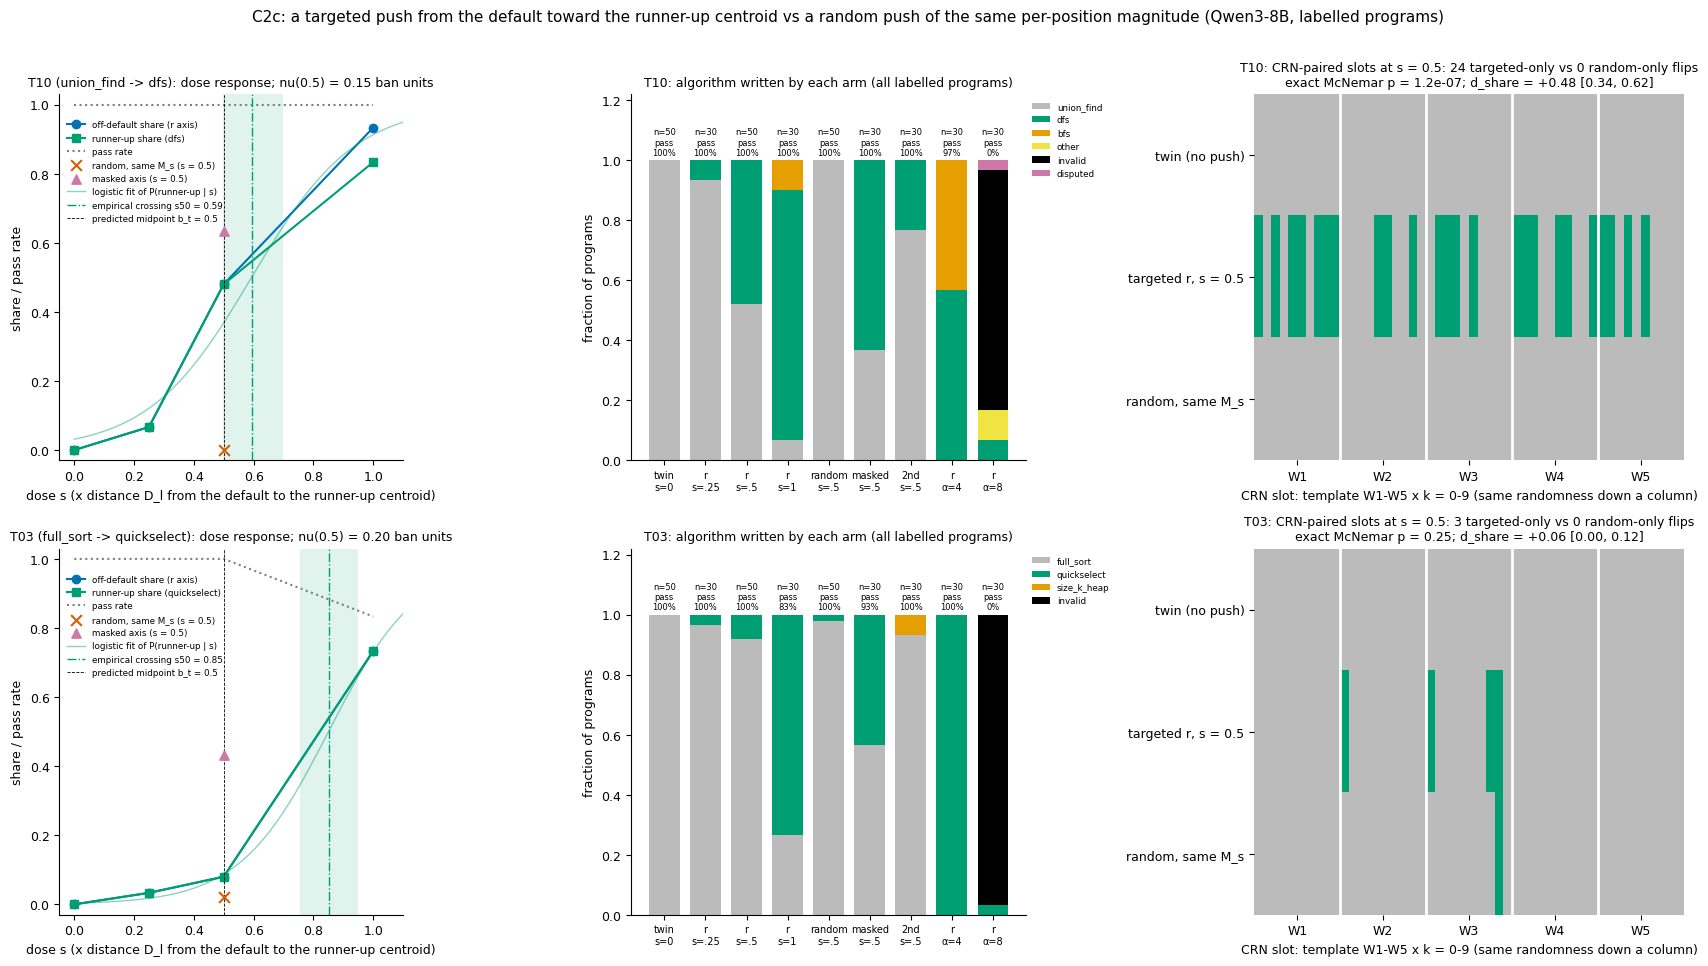

In [16]:
OI = ["#0072B2", "#E69F00", "#009E73", "#D55E00", "#CC79A7", "#56B4E9", "#F0E442", "#000000"]   # analysis/figures.py
plt.rcParams.update({"font.size": 9, "axes.spines.top": False, "axes.spines.right": False})
from sklearn.linear_model import LogisticRegression

SHOW = [t for t in ("T10", "T03") if t in res["per_task"]]
SHORT = {"TWIN": "twin\ns=0", "C2C_r_s0.25": "r\ns=.25", "C2C_r_s0.5": "r\ns=.5", "C2C_r_s1.0": "r\ns=1",
         "rand": "random\ns=.5", "C2C_rm_s0.5": "masked\ns=.5", "C2C_r2_s0.5": "2nd\ns=.5",
         "SWEEP_r_a4.0": "r\nα=4", "SWEEP_r_a8.0": "r\nα=8"}
fig, axs = plt.subplots(len(SHOW), 3, figsize=(17, 4.9 * len(SHOW)), squeeze=False,
                        gridspec_kw={"width_ratios": [1.0, 1.15, 1.25]})
for row, t in zip(axs, SHOW):
    r, a = res["per_task"][t], res["per_task"][t]["arms"]
    d, ru = DEFAULT4[t], r["runner_up"]
    rk = [k for k in a if k.startswith("C2C_rand")]
    rr = committed_rows(rows, t)
    labs = [d, ru] + [c for c in catalogue(t) if c not in (d, ru)] + ["other", "invalid", "disputed"]
    col = {d: "#BBBBBB", ru: OI[2], "other": OI[6], "invalid": OI[7], "disputed": OI[4]}
    _spare = iter([OI[1], OI[5], OI[3], OI[0], "#999933", "#882255", "#44AA99", "#117733"])
    for c in labs:
        if c not in col:
            col[c] = next(_spare)

    # (1) dose response along r, drawn as in analysis/figures.py fig4, plus the logistic fit behind crossing()
    ax = row[0]
    ss, sh, rus, hl = [], [], [], []
    for s, k in ((0.0, "TWIN"), (0.25, "C2C_r_s0.25"), (0.5, "C2C_r_s0.5"), (1.0, "C2C_r_s1.0")):
        if k in a:
            ss.append(s); sh.append(a[k]["share"]); rus.append(a[k]["runner_up_share"]); hl.append(a[k]["pass"])
    ax.plot(ss, sh, "-o", color=OI[0], label="off-default share (r axis)")
    ax.plot(ss, rus, "-s", color=OI[2], label=f"runner-up share ({ru})")
    ax.plot(ss, hl, ":", color="grey", label="pass rate")
    if rk:
        ax.scatter([0.5], [a[rk[0]]["share"]], marker="x", s=60, color=OI[3], zorder=4,
                   label="random, same M_s (s = 0.5)")
    if "C2C_rm_s0.5" in a:
        ax.scatter([0.5], [a["C2C_rm_s0.5"]["share"]], marker="^", s=45, color=OI[4], zorder=4,
                   label="masked axis (s = 0.5)")
    pts = [(s, int(x["label"] == ru)) for s, k in ((0.0, "TWIN"), (0.25, "C2C_r_s0.25"), (0.5, "C2C_r_s0.5"),
                                                   (1.0, "C2C_r_s1.0"))
           for x in rr if x["arm"] == k and x["label"] not in EXCLUDE]
    lr = LogisticRegression(C=1e4).fit(np.array([[s] for s, _ in pts]), np.array([y for _, y in pts]))
    grid = np.linspace(0, 1.1, 200)
    ax.plot(grid, lr.predict_proba(grid[:, None])[:, 1], color=OI[2], lw=1, alpha=0.45,
            label="logistic fit of P(runner-up | s)")
    cr = r["crossing"]
    if cr.get("ci"):
        ax.axvspan(cr["ci"][0], cr["ci"][1], color=OI[2], alpha=0.12, lw=0)
    ax.axvline(cr["s50"], color=OI[2], lw=1, ls="-.", label=f"empirical crossing s50 = {cr['s50']:.2f}")
    ax.axvline(0.5, color="k", lw=0.6, ls="--", label="predicted midpoint b_t = 0.5")
    ax.set_ylim(-0.03, 1.03)
    ax.set_xlim(-0.05, 1.1)
    ax.set_title(f"{t} ({d} -> {ru}): dose response; nu(0.5) = {r['nu_0.5']:.2f} ban units", fontsize=9)
    ax.set_xlabel("dose s (x distance D_l from the default to the runner-up centroid)")
    ax.set_ylabel("share / pass rate")
    ax.legend(fontsize=6.3, frameon=False, loc="upper left", bbox_to_anchor=(0.0, 0.95))

    # (2) what every arm wrote: label composition of all its programs
    ax = row[1]
    order = [k for k in ["TWIN", "C2C_r_s0.25", "C2C_r_s0.5", "C2C_r_s1.0"] + rk +
             ["C2C_rm_s0.5", "C2C_r2_s0.5", "SWEEP_r_a4.0", "SWEEP_r_a8.0"] if k in a]
    bottom = np.zeros(len(order))
    for c in labs:
        v = np.array([a[k]["composition"].get(c, 0.0) for k in order])
        if v.sum() > 0:
            ax.bar(range(len(order)), v, bottom=bottom, color=col[c], width=0.75, label=c)
            bottom += v
    for i, k in enumerate(order):
        ax.text(i, 1.01, f"n={a[k]['n']}\npass\n{a[k]['pass']:.0%}", ha="center", va="bottom", fontsize=6)
    ax.set_xticks(range(len(order)), [SHORT["rand" if k.startswith("C2C_rand") else k] for k in order], fontsize=7)
    ax.set_ylim(0, 1.22)
    ax.set_ylabel("fraction of programs")
    ax.set_title(f"{t}: algorithm written by each arm (all labelled programs)", fontsize=9)
    ax.legend(fontsize=6.3, frameon=False, loc="upper left", bbox_to_anchor=(0.995, 1.0))

    # (3) the CRN pairing at s = 0.5: same slot = same random numbers, so a colour change is a flip caused by the push
    ax = row[2]
    keys = sorted({(x["template"], int(x["sample_id"])) for x in rr if x["arm"] == "C2C_r_s0.5"})
    lab_of = {(x["arm"], x["template"], int(x["sample_id"])): x["label"] for x in rr}
    strip = [("TWIN", "twin (no push)"), ("C2C_r_s0.5", "targeted r, s = 0.5"), (rk[0], "random, same M_s")]
    Mx = np.array([[labs.index(lab_of[(arm, w, k)]) for (w, k) in keys] for arm, _ in strip])
    ax.imshow(Mx, cmap=ListedColormap([col[c] for c in labs]), vmin=-0.5, vmax=len(labs) - 0.5, aspect="auto",
              interpolation="nearest")
    for i in range(1, 5):
        ax.axvline(i * 10 - 0.5, color="w", lw=2)
    ax.set_yticks(range(len(strip)), [nm for _, nm in strip])
    ax.set_xticks([i * 10 + 4.5 for i in range(5)], ["W1", "W2", "W3", "W4", "W5"])
    ax.set_xlabel("CRN slot: template W1-W5 x k = 0-9 (same randomness down a column)")
    ax.spines[:].set_visible(False)
    tv = r["targeted_vs_random"]
    ax.set_title(f"{t}: CRN-paired slots at s = 0.5: {tv['flips_targeted_only']} targeted-only vs "
                 f"{tv['flips_random_only']} random-only flips\nexact McNemar p = {tv['mcnemar_p']:.2g}; "
                 f"d_share = {tv['d_share']:+.2f} [{tv['d_share_ci'][0]:.2f}, {tv['d_share_ci'][1]:.2f}]", fontsize=9)
fig.suptitle("C2c: a targeted push from the default toward the runner-up centroid vs a random push of the same "
             "per-position magnitude (Qwen3-8B, labelled programs)", fontsize=11)
fig.tight_layout(rect=[0, 0, 1, 0.97])
plt.show()

### The two recomputed tasks in context
T10 and T03 are the two extremes. The full run's table (published `results/c2c.json`, all 6 movable tasks; shipped in the data's metadata) shows why the committed verdict is DISCONFIRM: on T2, T05, T06 and T1 the midpoint dose does nothing, and the targeted push cannot be told apart from the matched random push.

In [17]:
# The full run's C2c table (published results/c2c.json, all 6 movable tasks); the recomputed tasks are marked.
def _f(x, fmt="{:.2f}"):
    return "-" if x is None or (isinstance(x, float) and math.isnan(x)) else fmt.format(x)


pub = data["metadata"]["published_c2c"]
print("Full run, all 6 movable tasks (published results/c2c.json):")
print(f"{'task':5s} {'default -> runner-up':26s} {'share s=.25/.5/1':>18s} {'random':>7s} {'flips T/R':>9s} "
      f"{'McNemar p':>9s} {'d_share [95% CI]':>20s} {'s50 [95% CI]':>19s} {'PASS':>5s}")
for t, p in pub["per_task"].items():
    a, tv, cr = p["arms"], p["targeted_vs_random"], p["crossing"]
    sh = "/".join(_f(a[k]["share"]) if k in a else "-" for k in ("C2C_r_s0.25", "C2C_r_s0.5", "C2C_r_s1.0"))
    rnd = a[next(k for k in a if k.startswith("C2C_rand"))]["share"]
    ci = cr.get("ci") or [None, None]
    dsh = f"{_f(tv['d_share'], '{:+.2f}')} [{_f(tv['d_share_ci'][0])}, {_f(tv['d_share_ci'][1])}]"
    s50 = f"{_f(cr['s50'])} [{_f(ci[0])}, {_f(ci[1])}]"
    flips = f"{tv['flips_targeted_only']}/{tv['flips_random_only']}"
    mark = "   <- recomputed in this notebook" if t in res["per_task"] else ""
    print(f"{t:5s} {DEFAULT4[t] + ' -> ' + p['runner_up']:26s} {sh:>18s} {_f(rnd):>7s} {flips:>9s} "
          f"{_f(tv['mcnemar_p'], '{:.2g}'):>9s} {dsh:>20s} {s50:>19s} {str(p['c2c_pass']):>5s}{mark}")
v = pub["verdict"]
print(f"\nCommitted C2c verdict: PASS on {v['n_tasks_pass']}/6 tasks, targeted-minus-random CIs include 0 on "
      f"{v['n_tasks_ci_include_0']}/6 -> {v['reading']} (median alpha of the confirmed random escapes = "
      f"{v['median_alpha_confirmed_random']})")

Full run, all 6 movable tasks (published results/c2c.json):
task  default -> runner-up         share s=.25/.5/1  random flips T/R McNemar p     d_share [95% CI]        s50 [95% CI]  PASS
T03   full_sort -> quickselect       0.03/0.08/0.73    0.02       3/0      0.25   +0.06 [0.00, 0.12]   0.85 [0.76, 0.95] False   <- recomputed in this notebook
T2    dijkstra -> bf_spfa            0.00/0.02/0.07    0.00       1/0         1   +0.02 [0.00, 0.06]   1.69 [1.16, 6.74] False
T05   hash_map -> brute_force        0.00/0.00/0.00    0.00       0/0         1   +0.00 [0.00, 0.00]            - [-, -] False
T10   union_find -> dfs              0.07/0.48/0.93    0.00      24/0   1.2e-07   +0.48 [0.34, 0.62]   0.59 [0.50, 0.70]  True   <- recomputed in this notebook
T06   hash_set -> sort_adjacent      0.00/0.00/0.00    0.00       0/0         1   +0.00 [0.00, 0.00]            - [-, -] False
T1    bfs -> dfs                     0.00/0.04/0.00    0.00       2/0       0.5   +0.04 [0.00, 0.10]   5.68 [4.4

## Takeaways
- **T10 (connected components): the centroid geometry is causally exact.** The push moves the task-spec state halfway (s = 0.5) toward the DFS centroid. That is only 0.15 ban units, about a tenth of the random pushes' size. It makes 48% of programs correct DFS, while a random push of the same per-position magnitude flips none of the 50 CRN-paired slots (24 / 0 flips, exact McNemar p = 1.2e-7). The empirical 50% crossing, s50 = 0.59 [0.50, 0.70], sits at the predicted Voronoi midpoint b_t = 0.5.
- **T03 (k-th smallest):** the same midpoint dose barely moves the model: 8% quickselect vs 2% for the random push, and the CI of the difference touches 0. The crossing lies at s = 0.85, and the name-free (masked) axis is stronger than the named one (43% vs 8%).
- **Full run:** on 5 of 6 movable tasks the targeted push at b_t cannot be told apart from the matched random push, so C2c is **disconfirmed by its committed rule**. Far beyond the midpoint (α = 8 ban units) the programs break: most are labelled `invalid`. Together with C2a (the projection share does not rank random pushes) and the decomposition (removing the plan component keeps the effect), the artifact concludes that **the plan subspace is real, but random pushes do not act through it**. Only on T10 does a push along the plan geometry switch the algorithm at the predicted dose. No push produced a correct novel algorithm (0 of 10,651).
- **Going further:** the other analyses need the repository's `data/` (13,500 labelled programs) and `predictions/`. They cover all six tasks, C2a, the decomposition, C2b, C3b and the geometry, and run with `python method.py analyze`. Regenerating the programs needs the GPU stages (`gpu1`, `gpu2`, about 2.5 GPU-hours on a 16 GB GPU) and the Qwen3-8B weights.
